项目总结
本项目基于 15 万条电商交易数据，使用 Python (Pandas, Matplotlib) 进行了全流程的数据清洗、多表关联与可视化分析。从产品、地域、客户、时间四个维度挖掘了业务问题，得出了“普通消费者是核心创收群体”、“美国市场贡献断层利润”、“电子产品为高利润现金牛”等核心结论，并给出了针对性的运营建议。

In [1]:
import pandas as pd

In [2]:
df_customer = pd.read_csv('customer_master.csv')
df_order = pd.read_csv('order_items.csv')
df_product = pd.read_csv('product_catalog.csv')
display(df_customer.head(3))
display(df_order.head(3))
display(df_product.head(3))

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9


展示客户表、订单表和产品表的前3行

In [7]:
print(df_order.isnull().sum())
df_merged = pd.merge(df_order, df_product, on='product_id', how='left')
display(df_merged[['order_id','product_category','quantity','net_sales','profit']].head(5))

order_id               0
product_id             0
quantity               0
unit_price             0
discount_percentage    0
discount_amount        0
gross_sales            0
tax_amount             0
shipping_cost          0
net_sales              0
product_cost           0
profit                 0
dtype: int64


,order_id,product_category,quantity,net_sales,profit
0,ORD-301242,Health & Wellness,2,351.88,172.12
1,ORD-301242,Fashion,3,593.52,172.92
2,ORD-773460,Jewelry,4,1919.32,-65.84
3,ORD-773460,Beauty & Personal Care,4,99.09,43.37
4,ORD-449374,Grocery,3,19.42,12.53


输出订单表为空的和，合并订单表和产品表，并展示order_id,product_category,quantity,net_sales,profit的前5行

In [23]:
df_merged=df_merged.drop_duplicates()
top_category=df_merged.groupby('product_category')['quantity'].sum().sort_values(ascending=False)
display(top_category.head(3))

product_category
Sports & Outdoors    64752
Books & Media        62305
Health & Wellness    62054
Name: quantity, dtype: int64

删除重复数据，产品类别按销量由大到小排序并展示销量TOP3

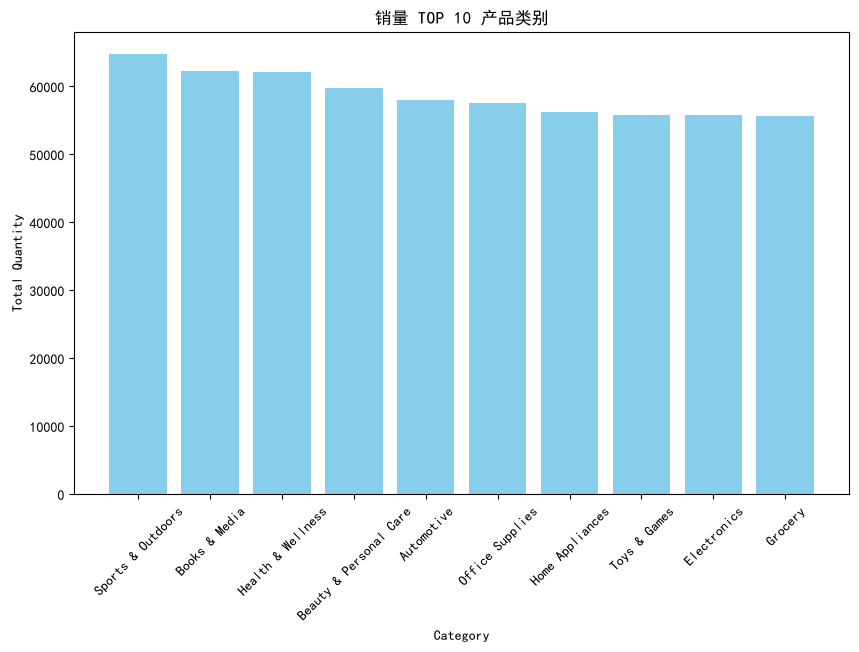

In [54]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False
top10 = df_merged.groupby('product_category')['quantity'].sum().sort_values(ascending=False).head(10)
categories = top10.index
values = top10.values
plt.figure(figsize=(10,6))
plt.bar(categories,values,color='skyblue')
plt.title('销量 TOP 10 产品类别')
plt.xlabel('Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=45)
plt.show()

画出销量TOP10的柱状图

In [24]:
df_merged=df_merged.drop_duplicates()
top_category=df_merged.groupby('product_category')['profit'].sum().sort_values(ascending=False)
display(top_category.head(3))

product_category
Electronics        14103982.74
Jewelry            10391635.32
Home Appliances    10288878.45
Name: profit, dtype: float64

删除重复数据，产品类别按照利润有多到少排序并展示TOP3

核心洞察 1：销量与利润并不完全挂钩
通过对比发现，销量 TOP3 的类别与利润 TOP3 的类别存在显著差异。
销量最高的是Sports & Outdoors、Books & Media等，这说明这些属于高频低毛利商品：
而利润最高的类别是Electronics，这说明该类商品属于高客单价/高利润率商品。
建议：在运营策略上，可以用高频低毛利的商品做引流，同时搭配推销高毛利的商品来提升整体 ROI

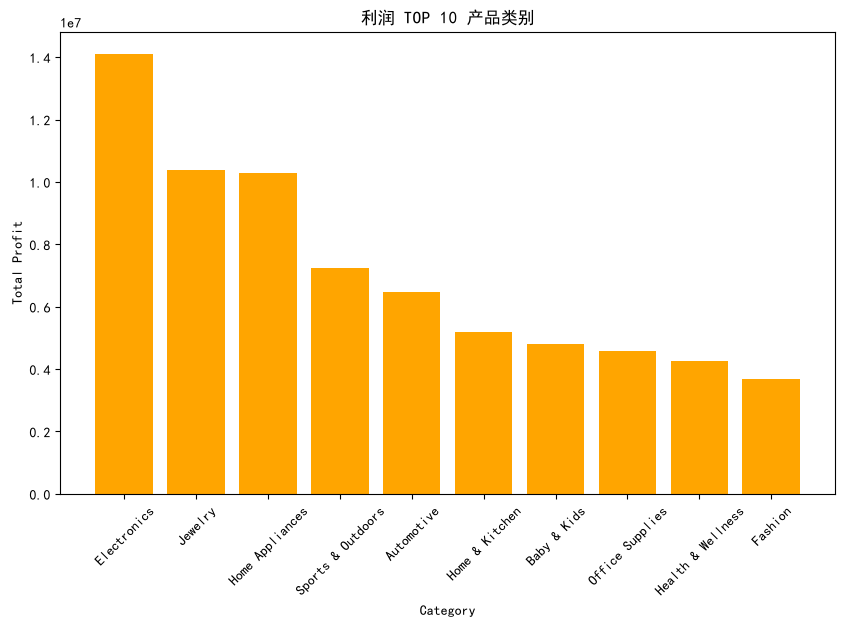

In [53]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False
top10 = df_merged.groupby('product_category')['profit'].sum().sort_values(ascending=False).head(10)
categories = top10.index
values = top10.values
plt.figure(figsize=(10,6))
plt.bar(categories,values,color='orange')
plt.title('利润 TOP 10 产品类别')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.show()

画出利润TOP10柱状图

核心洞察2：电子产品是利润的核心
从利润图看，电子产品遥遥领先，其次是珠宝和家电。对比销量图，虽然运动户外销量最高，但利润都不在前3。
建议：电子产品属于高客单价、高利润的“现金牛”业务，平台应加大电子产品的营销投入；同时可以对销量高的产品进行打折促销，为高利润产品引流。

In [31]:
df_final = pd.read_csv('ecommerce_sales_customer_analytics_150k.csv')
print(f"大表大小:{df_final.shape}")
print(df_final.columns.tolist())

大表大小:(138116, 46)
['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count']


In [40]:
country_count=df_final['customer_country'].nunique()
print(f"数据集中一共有{country_count}个国家。")
country_list=df_final['customer_country'].value_counts()
print("\n各个国家的订单数量排行：")
print(country_list)

数据集中一共有7个国家。

各个国家的订单数量排行：
customer_country
USA          82600
UK           20235
Germany      11593
Canada        7015
Australia     6794
India         5707
UAE           4172
Name: count, dtype: int64


经过数据探查，该数据集主要覆盖了7个国家的业务，其中排名前三的国家是USA，UK，Germany。说明该电商平台的业务主要集中在这几个区域。

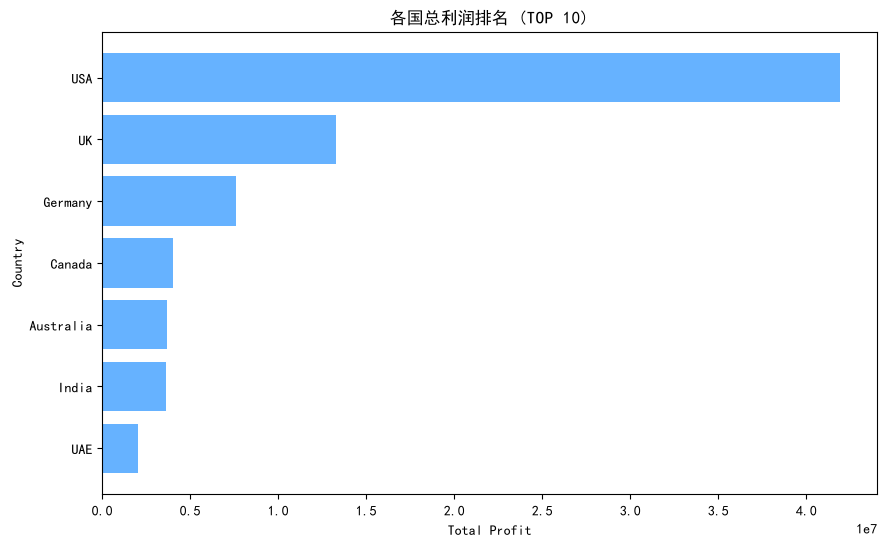

In [52]:
country_profit=df_final.groupby('customer_country')['profit'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,6))
plt.barh(country_profit.index, country_profit.values, color='#66B2FF')
plt.title('各国总利润排名 (TOP 10)')
plt.xlabel('Total Profit')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.show()

核心洞察3：利润高度集中于美国市场
通过个国家的利润图可以看出美国的利润额远超其他国家，其次是英国和德国。
建议：在运营资源有限的情况下，优先保障美国市场的供应链和营销投入；同时可以调研英国和德国市场，寻找第二增长曲线。

In [41]:
segment_counts=df_final['customer_segment'].value_counts()
print("各个客户群体的订单数量分布：")
print(segment_counts)

各个客户群体的订单数量分布：
customer_segment
Consumer    75636
Premium     34746
VIP         13957
Business    13777
Name: count, dtype: int64


In [44]:
segment_profit=df_final.groupby('customer_segment')['profit'].sum()
summary_table=pd.DataFrame({
    '订单量（人数）':segment_counts,
    '总利润':segment_profit
})
summary_table['单均利润']=summary_table['总利润']/summary_table['订单量（人数）']
display(summary_table)

,订单量（人数）,总利润,单均利润
customer_segment,,,
Business,13777,7782525.28,564.892595
Consumer,75636,42819790.02,566.129753
Premium,34746,18177727.78,523.160300
VIP,13957,7366352.68,527.789115


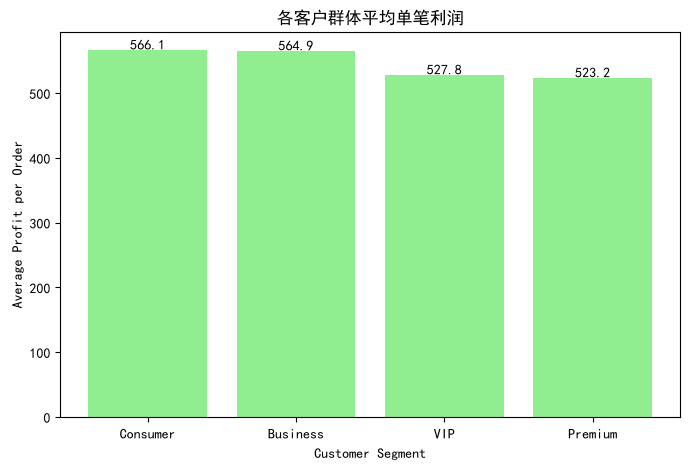

In [51]:
avg_profit=summary_table['单均利润'].sort_values(ascending=False)
plt.figure(figsize=(8,5))
plt.bar(avg_profit.index,avg_profit.values,color='lightgreen')
plt.title('各客户群体平均单笔利润')
plt.xlabel('Customer Segment')
plt.ylabel('Average Profit per Order')
for i,v in enumerate(avg_profit.values):
    plt.text(i,v + 1,f"{v:.1f}",ha='center')
plt.show()

核心洞察4：普通消费者是量价齐高的核心
结合订单量，总利润和单均利润来看，平台呈现出反直觉的商业规律：
1 普通消费者不仅贡献了最大的订单基数和总利润，其“单均利润”也位居第一。
2. 原本被认为高净值的VIP与Premium客户，订单量较少，且单均利润垫底。
建议：平台应将核心资源倾斜于维护普通消费者，利用高频商品持续引流；同时必须重新审视 VIP 权益体系，赋予其更高的专属附加值，以激活高净值用户的消费潜力。

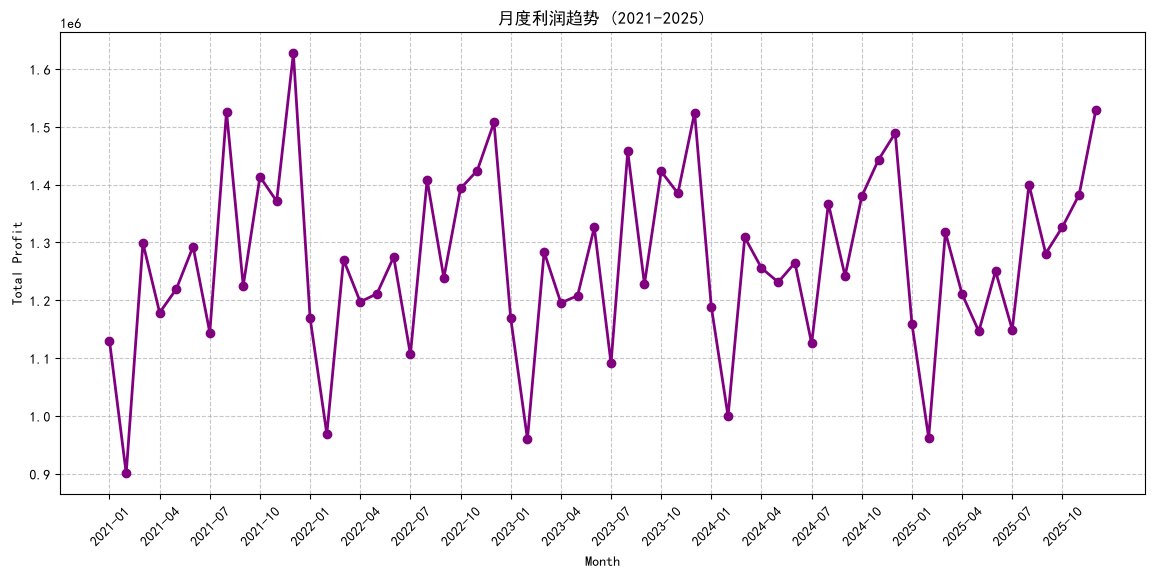

In [50]:
df_final['order_date'] = pd.to_datetime(df_final['order_date'])
df_final['year_month'] = df_final['order_date'].dt.to_period('M')
monthly_profit = df_final.groupby('year_month')['profit'].sum().sort_index()
plt.figure(figsize=(14, 6)) 
plt.plot(monthly_profit.index.astype(str), monthly_profit.values, marker='o', color='purple', linewidth=2)
plt.title('月度利润趋势 (2021-2025)')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(range(0, len(monthly_profit.index), 3), monthly_profit.index[::3].astype(str), rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

核心洞察5：利润呈现显著的周期性波动且淡旺季明显
从2021年至2025年的利润时间趋势来看，平台利润没有呈现单一的直线增长，而是呈现出规律的“锯齿状”周期波动。每年会有2-3次明显的利润高峰期，以及对应的业务低谷期，说明电商业务存在强烈的淡旺季属性。
建议：在旺季来临前，平台应提前做好供应链备货、物流运力储备及营销预算规划；在淡季，可安排系统维护、员工培训或开展清仓促销，以平滑利润波动。